In [7]:
import pandas as pd
import numpy as np
import  matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline


In [12]:
df = pd.read_excel("ABC Company Dataset.xlsx")
df.head()

,Name,Team,Number,Position,Age,Height,Weight,College,Salary
0,Avery Bradley,Boston Celtics,0,PG,25,2026-02-06 00:00:00,180,Texas,7730337.0
1,Jae Crowder,Boston Celtics,99,SF,25,2026-06-06 00:00:00,235,Marquette,6796117.0
2,John Holland,Boston Celtics,30,SG,27,2026-05-06 00:00:00,205,Boston University,NaN
3,R.J. Hunter,Boston Celtics,28,SG,22,2026-05-06 00:00:00,185,Georgia State,1148640.0
4,Jonas Jerebko,Boston Celtics,8,PF,29,2026-10-06 00:00:00,231,NaN,5000000.0


In [16]:
print(df.shape)
print(df.columns)

(458, 9)
Index(['Name', 'Team', 'Number', 'Position', 'Age', 'Height', 'Weight',
       'College', 'Salary'],
      dtype='object')


In [17]:
np.random.seed(42)
df['Height'] = np.random.randint(150, 181, size=len(df))
df.head()

,Name,Team,Number,Position,Age,Height,Weight,College,Salary
0,Avery Bradley,Boston Celtics,0,PG,25,156,180,Texas,7730337.0
1,Jae Crowder,Boston Celtics,99,SF,25,169,235,Marquette,6796117.0
2,John Holland,Boston Celtics,30,SG,27,178,205,Boston University,NaN
3,R.J. Hunter,Boston Celtics,28,SG,22,164,185,Georgia State,1148640.0
4,Jonas Jerebko,Boston Celtics,8,PF,29,160,231,NaN,5000000.0


In [18]:
print(df['Height'].min())
print(df['Height'].max())

150
180


In [19]:
df.isnull().sum()

Name         0
Team         0
Number       0
Position     0
Age          0
Height       0
Weight       0
College     84
Salary      11
dtype: int64

In [20]:
team_count = df['Team'].value_counts()
team_percentage = (team_count / len(df)) * 100
team_analysis = pd.DataFrame({
    'Employee Count': team_count,
    'Percentage': team_percentage
})
print(team_analysis)

                        Employee Count  Percentage
Team                                              
New Orleans Pelicans                19    4.148472
Memphis Grizzlies                   18    3.930131
Utah Jazz                           16    3.493450
New York Knicks                     16    3.493450
Milwaukee Bucks                     16    3.493450
Brooklyn Nets                       15    3.275109
Portland Trail Blazers              15    3.275109
Oklahoma City Thunder               15    3.275109
Denver Nuggets                      15    3.275109
Washington Wizards                  15    3.275109
Miami Heat                          15    3.275109
Charlotte Hornets                   15    3.275109
Atlanta Hawks                       15    3.275109
San Antonio Spurs                   15    3.275109
Houston Rockets                     15    3.275109
Boston Celtics                      15    3.275109
Indiana Pacers                      15    3.275109
Detroit Pistons                

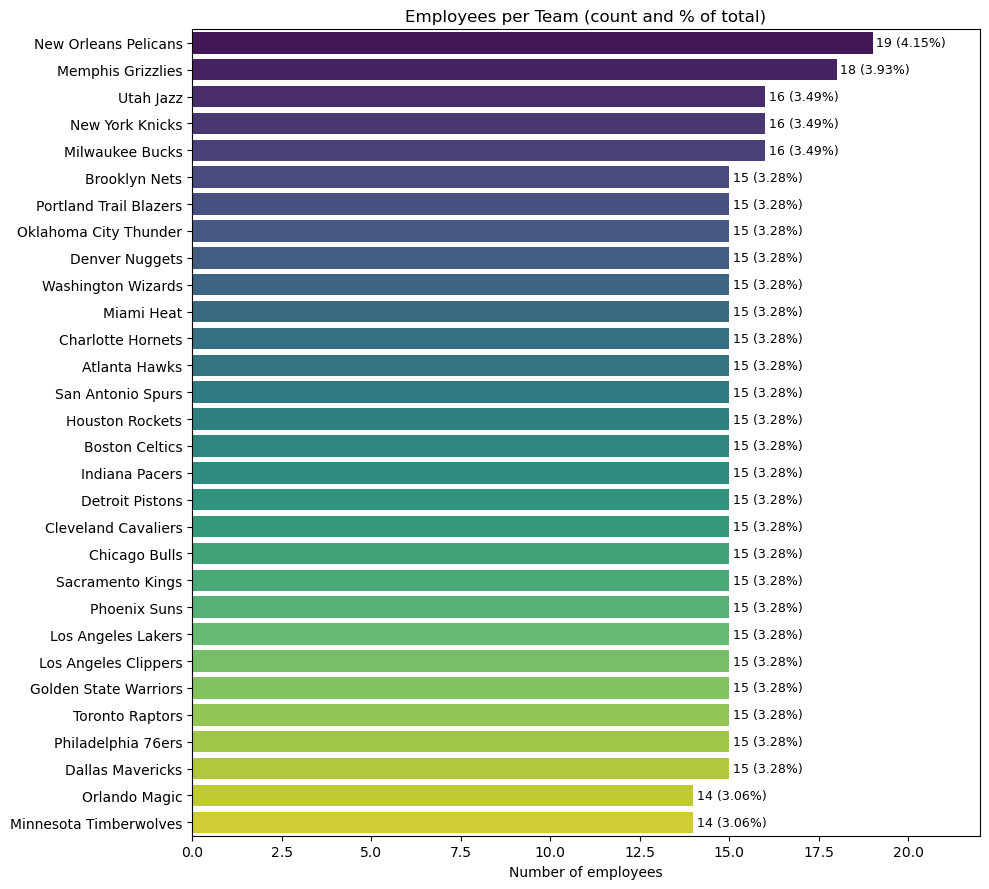

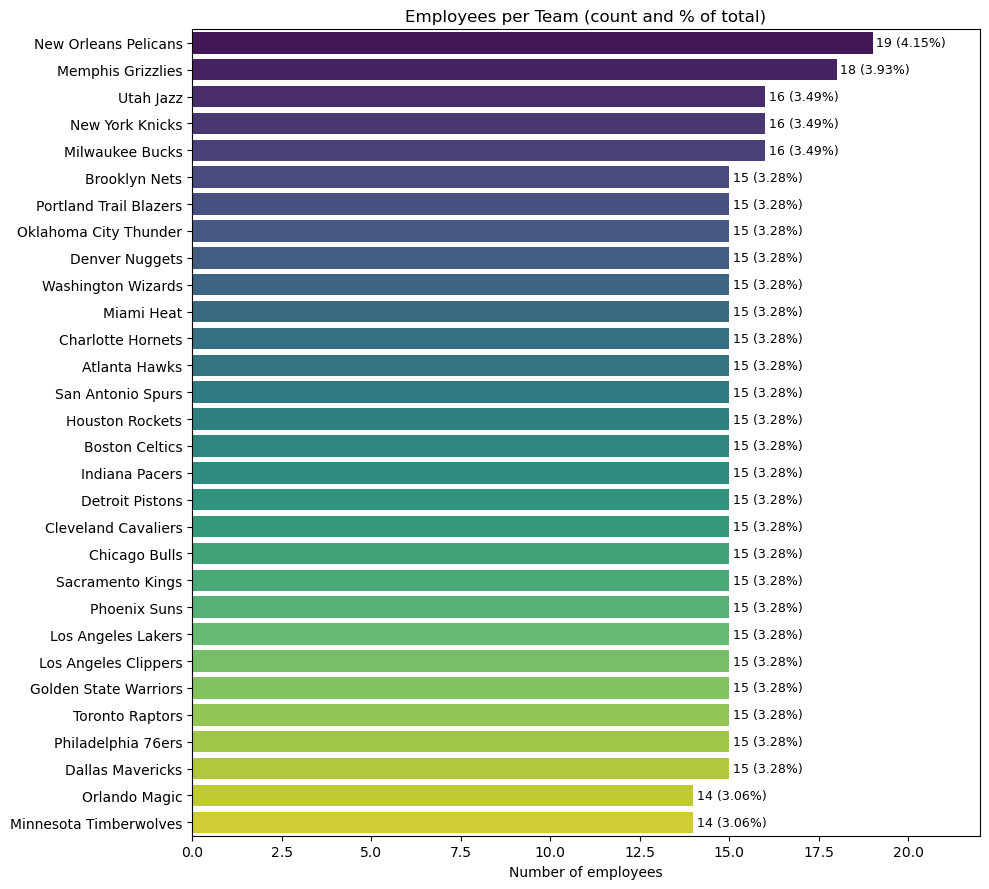

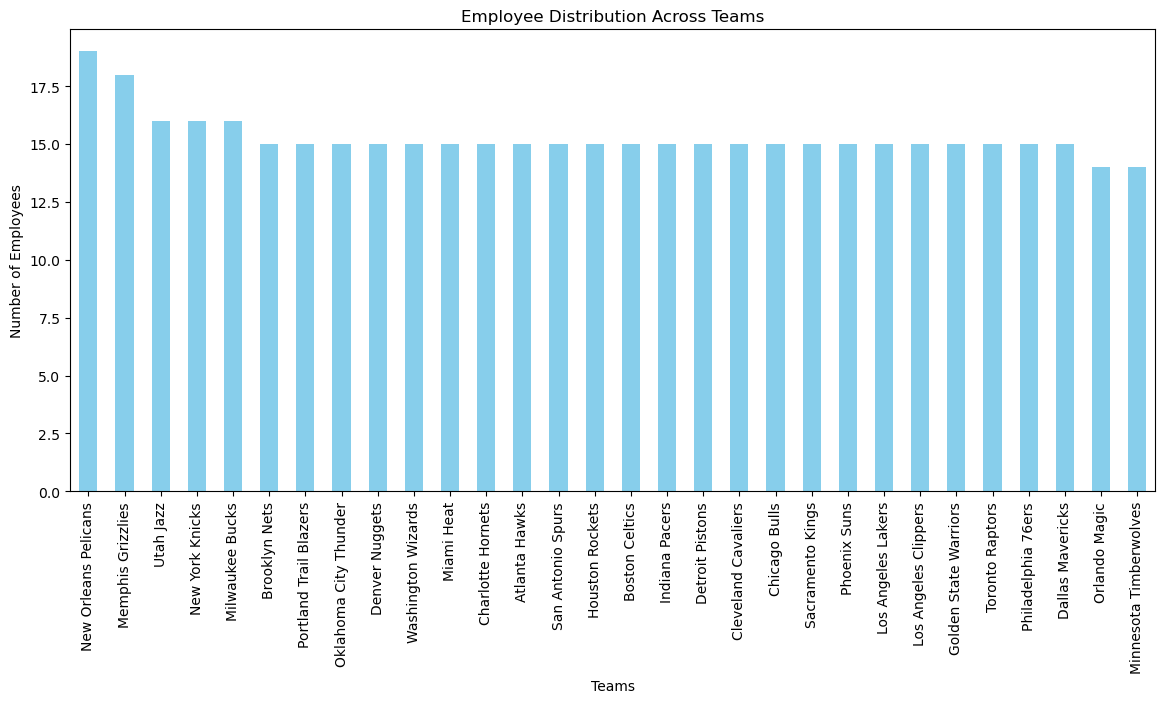

In [21]:
plt.figure(figsize=(14,6))
team_count.plot(kind='bar', color='skyblue')
plt.title('Employee Distribution Across Teams')
plt.xlabel('Teams')
plt.ylabel('Number of Employees')
plt.xticks(rotation=90)
plt.show()

In [22]:
position_count = df['Position'].value_counts()
print(position_count)

Position
SG    102
PF    100
PG     92
SF     85
C      79
Name: count, dtype: int64


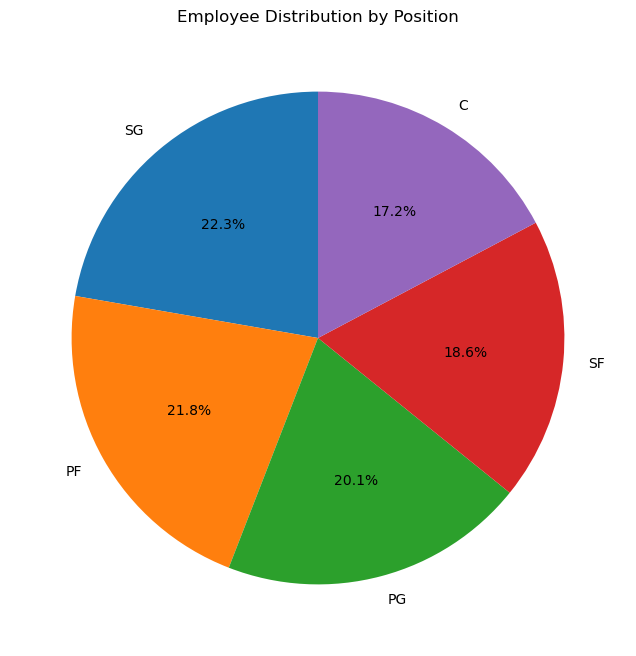

In [23]:
plt.figure(figsize=(8,8))
plt.pie(position_count,labels=position_count.index,autopct='%1.1f%%',startangle=90
)
plt.title('Employee Distribution by Position')
plt.show()

In [24]:
bins = [18, 25, 30, 35, 40]
labels = ['19-25', '26-30', '31-35', '36-40']
df['Age Group'] = pd.cut(df['Age'],bins=bins,labels=labels,include_lowest=True)
age_count = df['Age Group'].value_counts().sort_index()
print(age_count)

Age Group
19-25    200
26-30    167
31-35     68
36-40     23
Name: count, dtype: int64


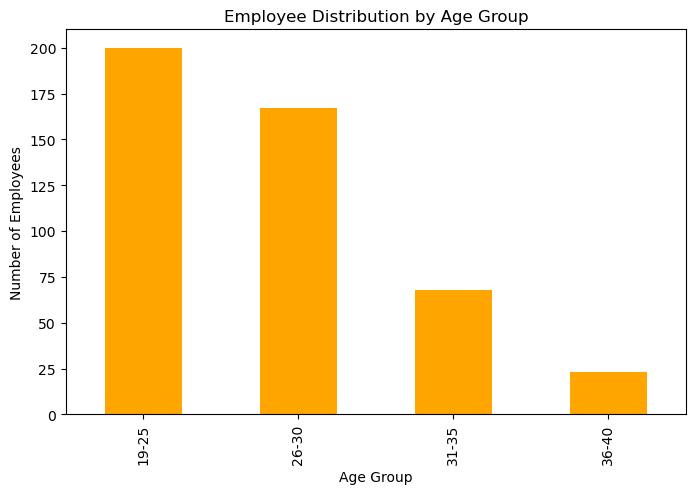

In [25]:
plt.figure(figsize=(8,5))
age_count.plot(kind='bar', color='orange')
plt.title('Employee Distribution by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Number of Employees')
plt.show()

In [26]:
team_salary = df.groupby('Team')['Salary'].sum()
team_salary = team_salary.sort_values(ascending=False
)
print(team_salary)

Team
Cleveland Cavaliers       106988689.0
Los Angeles Clippers       94854640.0
Oklahoma City Thunder      93765298.0
Golden State Warriors      88868997.0
Chicago Bulls              86783378.0
San Antonio Spurs          84442733.0
New Orleans Pelicans       82750774.0
Miami Heat                 82515673.0
Charlotte Hornets          78340920.0
Memphis Grizzlies          76550880.0
Washington Wizards         76328636.0
Houston Rockets            75283021.0
New York Knicks            73303898.0
Atlanta Hawks              72902950.0
Los Angeles Lakers         71770431.0
Sacramento Kings           71683666.0
Dallas Mavericks           71198732.0
Toronto Raptors            71117611.0
Milwaukee Bucks            69603517.0
Detroit Pistons            67168263.0
Indiana Pacers             66751826.0
Utah Jazz                  64007367.0
Phoenix Suns               63445135.0
Orlando Magic              60161470.0
Denver Nuggets             60121930.0
Minnesota Timberwolves     59709697.0
Boston 

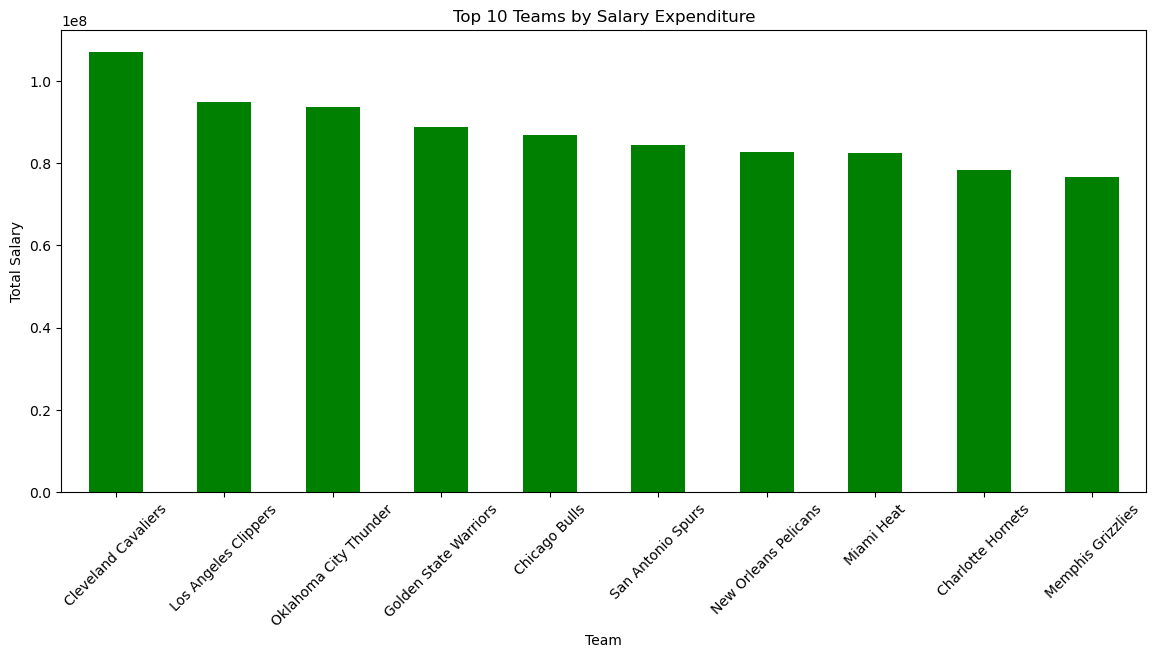

In [27]:
plt.figure(figsize=(14,6))
team_salary.head(10).plot(kind='bar',color='green')
plt.title('Top 10 Teams by Salary Expenditure')
plt.xlabel('Team')
plt.ylabel('Total Salary')
plt.xticks(rotation=45)
plt.show()

In [28]:
position_salary = df.groupby('Position')['Salary'].sum()
print(position_salary)

Position
C     466377332.0
PF    442560850.0
PG    446848971.0
SF    408020976.0
SG    396976258.0
Name: Salary, dtype: float64


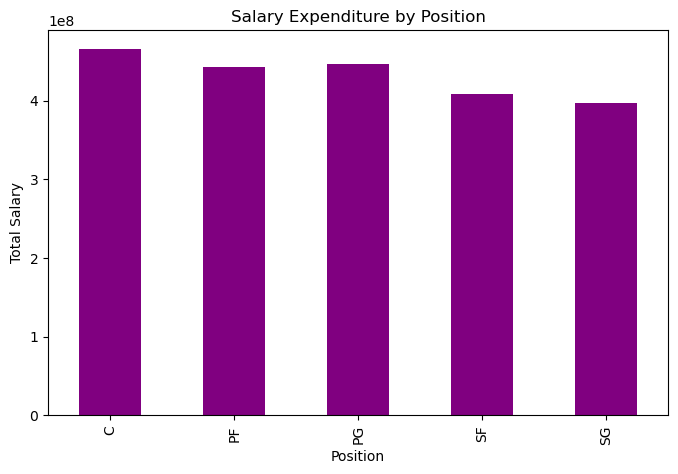

In [29]:
plt.figure(figsize=(8,5))
position_salary.plot(kind='bar',color='purple')
plt.title('Salary Expenditure by Position')
plt.xlabel('Position')
plt.ylabel('Total Salary')
plt.show()

In [30]:
correlation = df['Age'].corr(df['Salary'])
print("Correlation:", correlation)

Correlation: 0.21400941226570971


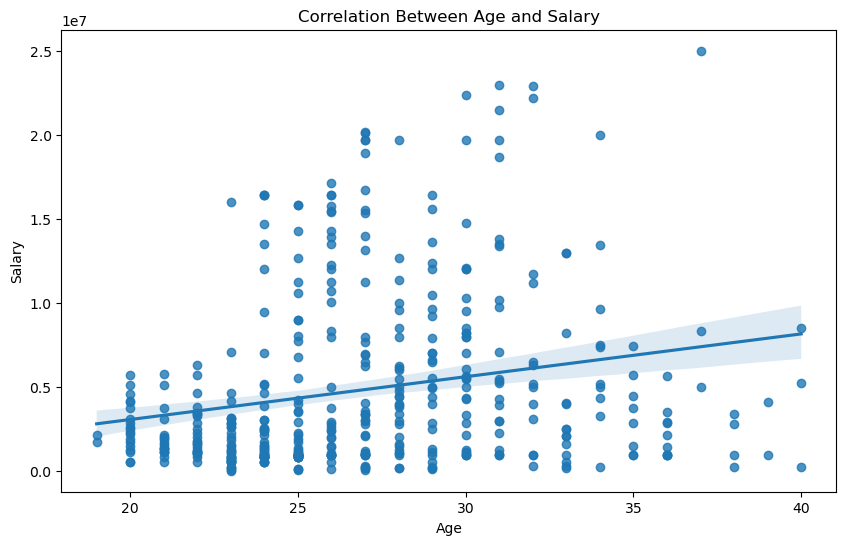

In [31]:
plt.figure(figsize=(10,6))
sns.regplot(data=df,x='Age', y='Salary')
plt.title('Correlation Between Age and Salary')
plt.xlabel('Age')
plt.ylabel('Salary')
plt.show()

In [32]:
print("ABC COMPANY DATA ANALYSIS")
print("-------------------------")
print("Total Employees:", len(df))
print("Total Teams:", df['Team'].nunique())
print("Most Employees in Team:",team_count.idxmax())
print("Most Common Position:",position_count.idxmax())
print("Predominant Age Group:",age_count.idxmax())
print("Highest Salary Team:",team_salary.idxmax())
print("Highest Salary Position:",position_salary.idxmax())
print("Age-Salary Correlation:",round(correlation, 3))

ABC COMPANY DATA ANALYSIS
-------------------------
Total Employees: 458
Total Teams: 30
Most Employees in Team: New Orleans Pelicans
Most Common Position: SG
Predominant Age Group: 19-25
Highest Salary Team: Cleveland Cavaliers
Highest Salary Position: C
Age-Salary Correlation: 0.214


In [33]:
df.to_excel('ABC_Company_Cleaned.xlsx',index=False
)
print("Dataset saved successfully!")

Dataset saved successfully!
